# Day 1 · The extract, and why a bag of codes fails

**Today's goal:** get the OMOP extract loaded as one event stream, understand the four
preprocessing decisions baked into it, and see the exact failure that motivates the rest
of the week.

### Summary

Every unsupervised method is a distance function plus a search procedure. Changing the
representation moves the answer more than changing the algorithm does, so the leverage is
upstream. Today is the upstream.

### Three things that all get called "pattern"

| Term | What it is | Built on | Auditable? |
|---|---|---|---|
| **Cluster** | a group of similar patients | Day 2 | partly |
| **Motif** | a recurring *ordered* subsequence | Day 3 | yes |
| **Embedding** | a direction in a learned space | Day 4 | no |

Zack has used "pattern" for all three. Deciding which is the deliverable is the single most
important scoping question on this project.

### Technique chosen per subtopic

| Subtopic | We use | Mentioned only |
|---|---|---|
| Similarity | **cosine** on binary codes | Jaccard, Dice, Gower, Mahalanobis |
| Linear reduction | **truncated SVD** | PCA (same thing, dense), ICA, factor analysis |
| Parts-based | **NMF** | archetypal analysis, sparse PCA |
| Non-linear view | **t-SNE** (ships with sklearn) | UMAP — better, `pip install umap-learn` |

## 0 · Getting the data

`ethos_omop.extract_omop()` is the extract script, refactored. Two differences from the
version you have been running:

* **`concept.csv` is slimmed** to the concept_ids the sample actually references. The full
  table is millions of rows; you almost never want it on disk.
* **`concept_ancestor` is dumped too**, restricted to rows touching the sample. That is what
  you need for ontology rollup — unspecified cardiac codes to their parents, drug products
  to ingredients.

Everything else is unchanged: `master_*` stays the source of truth, `ethos_dip` is excluded
on both `concept_id` and `source_concept_id` for every domain table, and standard-named
symlinks are written alongside so `meds_etl_omop` can find the files.

```python
# random sample, with Snowflake access
import ethos_omop as eo
eo.extract_omop(n_patients=10_000)       # -> omop_extract/
```

Or, to work a specific cohort instead of a random sample, pass a cohort-defining query —
raw SQL or a path to a `.sql` file — that returns `person_id`. Paths are relative to this
notebook's working directory (`repr_learn/`), so a file in the repo-root `sql/` folder needs
`../`:

```python
eo.extract_cohort("../sql/chest_pain_cohort.sql")   # -> data_input/
```

`extract_cohort()` runs your query to get the seed person_ids, then dumps the exact same
shape `extract_omop()` does (`master_*`, `person`, `death`, a slimmed `concept`) filtered to
that cohort — so every loader below works unchanged, just pointed at `OUT_DIR`.

Without Snowflake, or when you want data whose answer you already know:

```bash
python make_demo_extract.py 2000
```

The demo extract has the **same schema** — integer `concept_id`s resolved through
`concept.csv`, `master_*` table names, the symlinks — plus a `truth.csv` giving each
patient's planted trajectory archetype. Real extracts have no `truth.csv`. That absence is
the whole problem this course is about, and every notebook here works either way.

In [5]:
import os
import ethos_omop as eo

OUT_DIR     = "../data_input"                     # extract_cohort() output, relative to repr_learn/
COHORT_SQL  = "../sql/chest_pain_cohort.sql"   # relative to this notebook's cwd (repr_learn/)

# Runs once: if OUT_DIR is already populated, notebooks load from disk and never
# re-hit Snowflake. Delete OUT_DIR (or pick a different one) to force a re-pull.
if not os.path.isdir(OUT_DIR):
    eo.extract_cohort(COHORT_SQL, out_dir=OUT_DIR)
else:
    print(f"{OUT_DIR}/ already populated -- skipping extract_cohort(). "
          f"Delete it to re-pull from Snowflake.")

 pip install snowflake-connector-python[secure-local-storage]


Initiating login request with your identity provider. Press CTRL+C to abort and try again...
Going to open: https://ethoslife.okta.com/app/snowflake/exk1lfx2f6z1dVd7l0h8/sso/saml?SAMLRequest=lZJRb5swFIX%2FCvKewYZFJLGSVLRZtqztxhJSTX3zwCRWjE19TaH79TMkmbqHVtobMuf4O77nzq66SnrP3IDQao7CgCCPq1wXQu3naJet%2FAnywDJVMKkVn6MXDuhqMQNWyZomjT2oDX9qOFjPXaSA9j%2FmqDGKagYCqGIVB2pzuk3u72gUEMoAuLEOh86WAoRjHaytKcZt2wbtx0CbPY4IIZhMsVP1kg%2FoFaJ%2Bn1EbbXWu5cXSuTe9gQgxGfUIp3CE9Gy8Fuo0gvcov04ioF%2ByLPXT79sMecnldTdaQVNxs%2BXmWeR8t7k7BQCXYHObTMbjOAoa8DkD64cBKN2Wkh15rqu6se7awH3hkhdY6r1ww1ov56g%2BiiJqN91mFe2NTG%2FFlpHRE2uOj%2FD1UwfLRE5%2Fribp5112vYybHznyHi7VRn21a4CGr1VfqHVHJIp9MvXDOAvHNCI0HAXjKH5E3tIVKhSzg%2FOSmtuDBilKHuijZUM8Vtf4b3LMu2Moyy4q499h8VCMJTlMMIDGfWPotDR0iGAW%2Fz2KGX5tPy%2FgN9fJeplqKfIXb6VNxezblYVBOJyIwi8HKeUVEzIpCsMBXHVS6vbGcGbdnlvTcIQXJ%2Bq%2Fm774Aw%3D%3D&RelayState=ver%3A3-hint%3A22325597319909382-ETMsDgAAAaCrO7%2BGABRBRVMvQ0JDL1BLQ1M1UGFkZGluZwEAABAAEDbdklat1zMUmLNAJ84k%2BEYAAACgXBZOQzDdilD1P6oYc9li

 pip install snowflake-connector-python[secure-local-storage]


cohort seeded 150368 person_ids
person: 150368 rows
master_visit_occurrence: 19415483 rows
master_condition_occurrence: 20207541 rows
master_drug_exposure: 8480837 rows
master_procedure_occurrence: 12294763 rows
master_measurement: 8929800 rows
master_observation: 10374872 rows
death: 17 rows
concept: 30027 rows
concept_ancestor: 1124402 rows
linked data_input/visit_occurrence.csv -> master_visit_occurrence.csv
linked data_input/condition_occurrence.csv -> master_condition_occurrence.csv
linked data_input/drug_exposure.csv -> master_drug_exposure.csv
linked data_input/procedure_occurrence.csv -> master_procedure_occurrence.csv
linked data_input/measurement.csv -> master_measurement.csv
linked data_input/observation.csv -> master_observation.csv


In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 40)

DOMAINS = ['Visit', 'Condition', 'Drug', 'Procedure', 'Measurement']

concept  = eo.load_concept(OUT_DIR)
codesets = eo.build_codesets(concept, verbose=False)
events   = eo.tag_events(eo.load_events(OUT_DIR, domains=DOMAINS), codesets)
person   = eo.load_person(OUT_DIR)
truth    = eo.load_truth(OUT_DIR)                   # None against real data

print(f"events {events.shape}   patients {events.person_id.nunique()}")
print(f"codeset coverage: {events.in_codeset.mean():.1%} of events carry a clinical tag")
print(f"truth labels: {'present (DEMO extract)' if truth is not None else 'ABSENT (real data)'}")
events.head(6)

events (63284813, 10)   patients 150368
codeset coverage: 6.3% of events carry a clinical tag
truth labels: ABSENT (real data)


,person_id,concept_id,event_date,domain,vocabulary_id,concept_code,concept_name,token,tag,in_codeset
0,22,2212095,2019-04-25,Measurement,CPT4,80061,Lipid panel This panel must include the follow...,CPT4/80061,lipid_panel_this_panel,False
1,22,2212320,2019-04-25,Measurement,CPT4,82670,Estradiol; total,CPT4/82670,estradiol_total,False
2,22,2212816,2019-04-25,Measurement,CPT4,86376,"Microsomal antibodies (eg, thyroid or liver-ki...",CPT4/86376,microsomal_antibodies_,False
3,22,4017355,2019-04-25,Measurement,SNOMED,104994008,"Triiodothyronine, free measurement",SNOMED/104994008,triiodothyronine_free_,False
4,22,4068735,2019-04-25,Measurement,SNOMED,20436004,"Testosterone measurement, unbound",SNOMED/20436004,testosterone_measureme,False
5,22,4196731,2019-04-25,Measurement,SNOMED,313408009,Total thyroxine measurement,SNOMED/313408009,total_thyroxine_measur,False


In [8]:
print(eo.describe_extract(OUT_DIR).to_string(index=False))

                           file     rows     MB
master_condition_occurrence.csv 20207541 2951.8
    master_visit_occurrence.csv 19415483 2425.2
master_procedure_occurrence.csv 12294763 1819.2
         master_observation.csv 10374872 1277.2
         master_measurement.csv  8929800 1209.1
       master_drug_exposure.csv  8480837 1634.0
           concept_ancestor.csv  1124402   24.4
                     person.csv   150368   19.6
                    concept.csv    30027    3.9
                      death.csv       17    0.0


## 1 · Four decisions already made for you

Read these before trusting anything downstream. Each is a modelling choice, not a detail.

**1. Standard concepts only.** `load_events()` keeps `standard_concept == 'S'` and drops
`concept_id = 0` (unmapped). Note the exclusion idiom in the extract is
`IS DISTINCT FROM 'ethos_dip'`, not `<> 'ethos_dip'` — the latter silently drops NULLs.

**2. `concept_code` stays a string.** Never let pandas parse it as numeric; leading zeros
and alphanumeric codes both break.

**3. Claims carry a DATE, not a timestamp.** Same-day events have no true order.
`DOMAIN_ORDER` breaks ties deterministically — visit, then condition, procedure,
measurement, drug, observation. It is arbitrary and it is written down. Stanford's CLMBR
was built for minute-level resolution; we do not have that, and pretending otherwise is
where silent errors come from.

**4. There is no `observation_period` in the extract.** `observation_window()` derives a
proxy from first and last observed event, which **understates** the true window. Anyone
whose history starts near their first event is left-truncated: "no prior diagnosis" may
mean "not observed yet."

count    150368.0
mean       2140.0
std        2438.0
min           0.0
25%        1873.0
50%        2291.0
75%        2478.0
max       99935.0


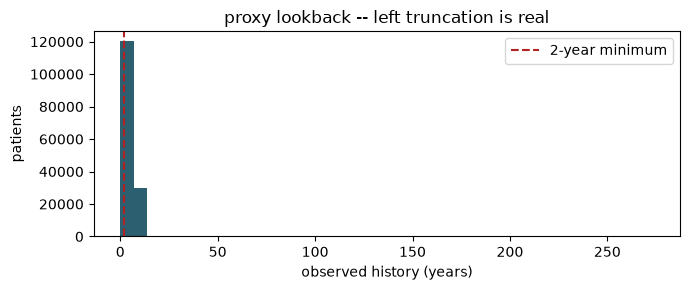


5899 patients (3.9%) have under 2 years of history.
Exclude them from any analysis that depends on the ABSENCE of a code.


In [11]:
win = eo.observation_window(events)
print(win.lookback_days.describe().round(0).to_string())

plt.figure(figsize=(7, 3))
plt.hist(win.lookback_days / 365.25, bins=40, color='#2C5F6F')
plt.axvline(2, ls='--', c='firebrick', label='2-year minimum')
plt.xlabel('observed history (years)'); plt.ylabel('patients')
plt.title('proxy lookback -- left truncation is real'); plt.legend()
plt.tight_layout(); plt.show()

SHORT = win.loc[win.lookback_days < 730, 'person_id']
print(f"\n{len(SHORT)} patients ({len(SHORT)/len(win):.1%}) have under 2 years of history.")
print("Exclude them from any analysis that depends on the ABSENCE of a code.")

## 2 · Concept sets, resolved by name

`CODESETS` in `ethos_omop.py` maps a clinical label to name patterns plus vocabularies.
Resolving by name rather than hardcoding concept_ids means the same notebook runs against
real Snowflake concepts and the demo extract alike.

**Always eyeball the resolution before trusting it.** This is the step where a bad regex
quietly poisons everything downstream.

In [12]:
eo.resolve(concept, ['letrozole'], vocabularies=['RxNorm', 'RxNorm Extension'])

,concept_id,concept_name,vocabulary_id,concept_code,domain_id
8874,19022830,letrozole 2.5 MG Oral Tablet,RxNorm,200064,Drug
7971,1315947,letrozole 2.5 MG Oral Tablet [Femara],RxNorm,153124,Drug


In [13]:
# On real data, roll a drug ingredient DOWN to all its products via concept_ancestor.
lz = codesets['letrozole']
print("letrozole concepts, direct:      ", len(lz))
print("letrozole concepts, + descendants:", len(eo.expand_descendants(lz)))

# And roll an unspecified diagnosis UP to its parents -- directly useful for the
# unspecified cardiac codes in the chest pain problem.
cp = codesets['chest_pain']
print("chest pain parents, 1 level up:  ", len(eo.roll_up(cp, levels=1)))

letrozole concepts, direct:       2
letrozole concepts, + descendants: 2
chest pain parents, 1 level up:   10


In [14]:
# `tag` collapses many concept_ids into one readable clinical label.
# Untagged events fall back to a slug of concept_name so sequences stay legible.
print(events.tag.value_counts().head(15).to_string())
print(f"\ntagged into a codeset: {events.in_codeset.mean():.1%}")

tag
pharmacy                  7328452
office_visit              5383597
therapeutic_procedure_    1029791
radiologic_examination     877483
venipuncture_for_blood     749103
essential_hypertension     716115
somatic_dysfunction_of     713882
ekg                        709305
anxiety                    636930
infectious_agent_detec     604962
chiropractic_manipulat     561811
chest_pain                 542493
complete_blood_count_w     524343
comprehensive_metaboli     521101
manual_therapy_techniq     505288

tagged into a codeset: 6.3%


Roughly a quarter to a third of events land in a curated codeset. That ratio is normal and
it is a useful number to report: it quantifies how much of the record your hand-built
domain knowledge actually covers. Zack's unknown-unknowns objection is exactly the other
two thirds.

## 3 · The bag of codes, and the exact failure

In [15]:
X = eo.bag_of_codes(events, min_count=20)
print(X.shape)
X.iloc[:5, :8]

(150368, 10877)


tag,0_05_ml_aflibercept_ay,0_07_ml_aflibercept_11,0_2_ml_glucagon_5_mg_m,0_2_ml_methotrexate_50,0_2_ml_sars_cov_2_covi,0_3_ml_bremelanotide_5,0_3_ml_enoxaparin_sodi,0_3_ml_methotrexate_50
person_id,,,,,,,,
22,0,0,0,0,0,0,0,0
50,0,0,0,0,0,0,0,0
67,0,0,0,0,0,0,0,0
68,0,0,0,0,0,0,0,0
321,0,0,0,0,0,0,0,0


In [ ]:
# Two patients with an IDENTICAL bag of codes and opposite clinical meaning.
weak = eo.weak_labels(events)                      # rule-based probe labels
lab  = weak.set_index('person_id').weak_label

both = [p for p in X.index
        if X.loc[p].get('letrozole', 0) == 1
        and X.loc[p].get('breast_cancer', 0) == 1
        and p in lab.index]

a = next((p for p in both if lab[p] == 'fertility'), None)
b = next((p for p in both if lab[p] == 'oncology'),  None)
assert a and b, ("No identical-bag pair found in this sample. Increase the extract "
                 "size, or inspect `both` to see which side is missing.")

print("bag-of-codes view -- indistinguishable:")
display(X.loc[[a, b], ['letrozole', 'breast_cancer']])

print("\nactual timelines -- obviously different:")
FOCUS = ['letrozole', 'breast_cancer', 'clomiphene', 'mastectomy',
         'anastrozole', 'infertility', 'breast_biopsy']
for pid in (a, b):
    s = events[(events.person_id == pid) & events.tag.isin(FOCUS)]
    print(f"\n  person_id {pid}  ({lab[pid]})")
    print(s[['event_date', 'tag']].drop_duplicates('tag').to_string(index=False))

**That is the motivation for the whole week.** Identical features, opposite risk. The
information lives in the order, and the representation threw it away.

This is not a modelling failure. No estimator can recover something the input does not
contain.

### On `weak_labels()`

There are no adjudicated labels in claims data. `weak_labels()` builds probe labels for the
letrozole indication from **corroborating co-evidence only** — clomiphene, gonadotropins and
infertility diagnoses on one side; mastectomy, biopsy, tamoxifen and anastrozole on the
other. Patients with both kinds of evidence, or neither, are dropped, and the counts are
printed so you can see how many.

**The time delta is deliberately not used.** If you label by "drug before diagnosis" and
then test whether the time delta predicts the label, you get perfect accuracy by
construction and have learned nothing. These labels are for evaluation, never features.

## 4 · Distance metrics disagree

In [ ]:
from sklearn.metrics import pairwise_distances

Xv  = X.values.astype(float)
sub = Xv[:400]
for m in ['euclidean', 'cosine', 'jaccard']:
    D  = pairwise_distances(sub, metric=m)
    iu = np.triu_indices(len(sub), 1)
    print(f"{m:10s} mean={D[iu].mean():.3f}  sd={D[iu].std():.3f}")

pos = list(X.index).index(a)
print()
for m in ['euclidean', 'cosine', 'jaccard']:
    D  = pairwise_distances(Xv[pos:pos+1], Xv, metric=m)[0]
    nn = [X.index[i] for i in np.argsort(D)[1:6]]
    print(f"{m:10s} neighbours of {a}: {[lab.get(p, '?') for p in nn]}")

**Rule of thumb for claims: use cosine on binary or count code vectors.** Euclidean punishes
patients simply for having long histories, so the distance ends up driven by utilisation
volume rather than clinical content — which in your data is partly a function of what got
ordered during underwriting.

## 5 · The curse of dimensionality

On the full Ethos vocabulary you will have tens of thousands of columns, not the few dozen
here. At that width every pair of patients becomes equidistant and "nearest neighbour" stops
meaning anything.

In [ ]:
rng = np.random.default_rng(0)
print(f"{'dims':>6} {'min/max distance ratio':>24}")
for d in [10, 50, 200, 1000, 5000]:
    Zr = (rng.random((200, d)) < 0.02).astype(float)     # sparse, like code data
    D  = pairwise_distances(Zr)
    iu = np.triu_indices(200, 1)
    print(f"{d:>6} {D[iu].min() / D[iu].max():>24.3f}")
print("\nRatio -> 1 means every patient is equally far from every other.")

## 6 · Truncated SVD and NMF

In [ ]:
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.preprocessing import normalize

Xn  = normalize(Xv)                                  # cosine geometry, done properly
svd = TruncatedSVD(n_components=min(30, Xv.shape[1] - 1), random_state=0).fit(Xn)
Z   = svd.transform(Xn)

plt.figure(figsize=(7, 3))
plt.plot(np.cumsum(svd.explained_variance_ratio_), marker='o', ms=3)
plt.axhline(0.8, ls='--', c='grey')
plt.xlabel('components'); plt.ylabel('cumulative variance')
plt.title('SVD scree -- where to truncate'); plt.tight_layout(); plt.show()

In [ ]:
# NMF factorises into non-negative PARTS, so each component reads as a set of
# co-occurring codes. Unlike SVD components you can name them.
nmf = NMF(n_components=8, init='nndsvd', random_state=0, max_iter=800).fit(Xv)
H   = pd.DataFrame(nmf.components_, columns=X.columns)
for k in range(8):
    print(f"component {k}: {H.iloc[k].sort_values(ascending=False).head(5).index.tolist()}")

Read those out loud — several are recognisable clinical bundles. **That is already a crude
motif catalog**, from a three-line factorisation, no deep learning involved. Keep it in your
pocket for the conversation about effort versus value.

## 7 · t-SNE, and how not to over-read it

In [ ]:
from sklearn.manifold import TSNE

colour = (truth.set_index('person_id').archetype.reindex(X.index)
          if truth is not None
          else lab.reindex(X.index).fillna('unlabelled'))

E = TSNE(n_components=2, init='pca', perplexity=30,
         random_state=0).fit_transform(Z[:, :min(24, Z.shape[1])])

fig, ax = plt.subplots(figsize=(7.5, 6))
for name, g in pd.DataFrame({'x': E[:,0], 'y': E[:,1],
                             'c': colour.values}).groupby('c', dropna=False):
    ax.scatter(g.x, g.y, s=7, alpha=.6, label=str(name))
ax.legend(fontsize=7, markerscale=2); ax.set_xticks([]); ax.set_yticks([])
ax.set_title('t-SNE of bag-of-codes' +
             (' -- coloured by planted truth (demo)' if truth is not None
              else ' -- coloured by weak label'))
plt.tight_layout(); plt.show()

On the demo extract, look at where **DM_STABLE** and **DM_PROGRESSIVE** land. They overlap
heavily, because their code *sets* are nearly identical — the only difference is that one
adds GLP-1 and insulin *later*. Day 3 separates them cleanly.

### Three things never to claim from a t-SNE or UMAP plot

1. Cluster **sizes** are meaningful. They are not.
2. **Distances between** clusters are meaningful. They are not.
3. Apparent **density** is meaningful. It is a function of perplexity.

Never cluster on the 2-D output. Cluster in SVD space; use the projection only to look.

## Exercises

1. Re-run `load_events(domains=['Condition','Drug'])`. How much does dropping measurements
   and visits change the picture? (On real data this is also the difference between a
   3-minute and a 30-minute load.)
2. Widen a codeset regex on purpose — add `'.*statin'` to the statin set — and see what
   `resolve()` pulls in. This is how bad codesets happen.
3. Rebuild `X` with counts instead of binary. Does cosine still behave?
4. Restrict to `lookback_days >= 730` and repeat. Which apparent structure disappears?

## Carry forward

`X`, `Z`, and the weak probe labels. Day 2 clusters `Z` and profiles back through `X`.